In [137]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

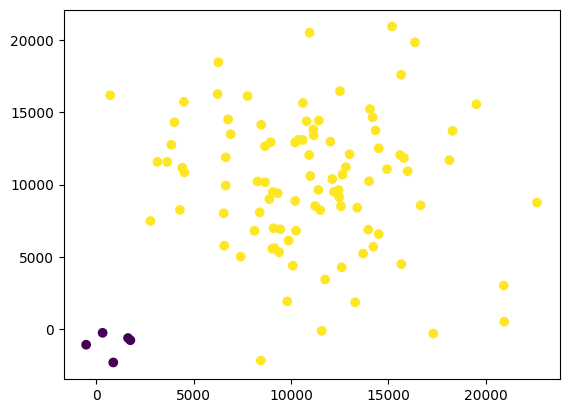

In [138]:
# Try changing the scaling factor. What happens as it gets big?
scaling_factor = 10000
random_state = 1
percent_cluster_one = 0.05

n_samples = (int(100 * percent_cluster_one),
             int(100 * (1 - percent_cluster_one)))
centers = [(0, 0), (scaling_factor, scaling_factor)]
stds = (0.1 * scaling_factor, 0.5 * scaling_factor)
X, y = make_blobs(
    n_samples=n_samples, random_state=random_state,
    centers=centers, cluster_std=stds)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

In [139]:
linreg = LinearRegression()
linreg.fit(X, y)
y_preds = (linreg.predict(X) > 0.5).astype(int)
linreg_acc = 100 * accuracy_score(y, y_preds)
print(f"LinReg Acc: {linreg_acc:.1f}%")

# Slight regularization helps logreg when we don't normalize our features
logreg = LogisticRegression(C=0.01)
logreg.fit(X, y)
y_preds = logreg.predict(X)
logreg_acc = 100 * accuracy_score(y, y_preds)
print(f"LogReg Acc: {logreg_acc:.1f}%")

LinReg Acc: 95.0%
LogReg Acc: 100.0%


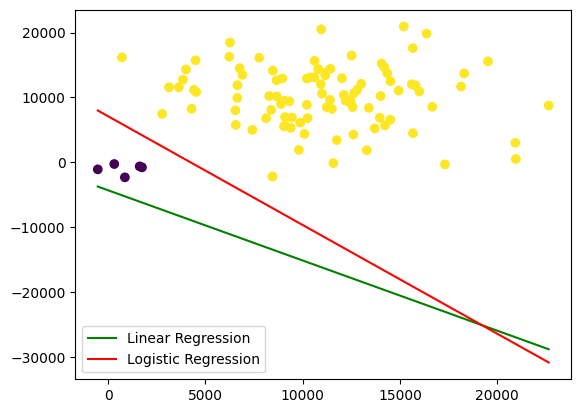

In [140]:
x1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
_ = plt.scatter(X[:, 0], X[:, 1], c=y)

(w1, w2), w0 = (linreg.coef_, linreg.intercept_)
x2 =  (0.5 - w1 * x1 - w0) / w2
_ = plt.plot(x1, x2, 'g-', label="Linear Regression")

(w1, w2), w0 = (logreg.coef_[0], logreg.intercept_)
x2 =  (- w1 * x1 - w0) / w2
_ = plt.plot(x1, x2, 'r-', label="Logistic Regression")
_ = plt.legend()